In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd


# Works when run from the repository root or this homework directory.
data_path = Path("car_fuel_efficiency_2026.csv")
if not data_path.exists():
    data_path = Path("02-regression/02-homework/car_fuel_efficiency_2026.csv")

features = ["engine_displacement", "horsepower", "vehicle_weight", "model_year"]
target = "fuel_efficiency_mpg"
df = pd.read_csv(data_path)[features + [target]].copy()
answers = {}
print(f"Dataset: {len(df):,} rows; {len(features)} predictors.")
display(df.head())

Dataset: 10,000 rows; 4 predictors.


,engine_displacement,horsepower,vehicle_weight,model_year,fuel_efficiency_mpg
0,2180,243.0,3870,2006,31.9
1,2390,272.0,4210,2008,31.3
2,2320,267.0,4240,1996,27.5
3,2130,258.0,4490,1989,28.5
4,2580,304.0,4510,1994,31.0


## EDA — Target distribution
The MPG distribution is approximately symmetric, with no pronounced long
right tail

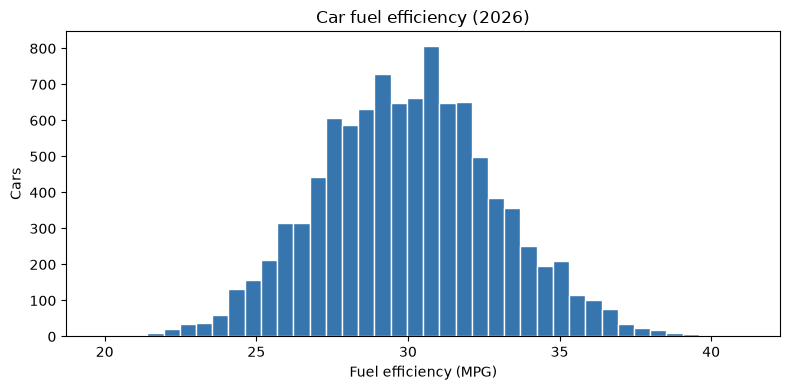

Target skewness: 0.080804


count    10000.000000
mean        29.997700
std          2.930245
min         19.800000
25%         28.000000
50%         30.000000
75%         31.900000
max         41.200000
Name: fuel_efficiency_mpg, dtype: float64

In [2]:
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(df[target], bins=40, color="#3675ad", edgecolor="white")
ax.set(title="Car fuel efficiency (2026)", xlabel="Fuel efficiency (MPG)", ylabel="Cars")
fig.tight_layout()
plt.show()
print(f"Target skewness: {df[target].skew():.6f}")
display(df[target].describe())

## Question 1 — Missing values
Count missing values after selecting only the assignment's columns.

In [3]:
missing_counts = df.isna().sum()
display(missing_counts.to_frame("missing_values"))
missing_column = missing_counts[missing_counts > 0].index.item()
answers[1] = missing_column
# (Q1): horsepower — 877 missing values.
print(f"(Q1): {answers[1]}")

,missing_values
engine_displacement,0
horsepower,877
vehicle_weight,0
model_year,0
fuel_efficiency_mpg,0


(Q1): horsepower


## Question 2 — Horsepower median
Pandas excludes missing observations when computing the median.

In [4]:
horsepower_median = float(df["horsepower"].median())
answers[2] = int(horsepower_median)
# SUBMIT THIS (Q2): 254.
print(f"Horsepower median: {horsepower_median}")
print(f"(Q2): {answers[2]}")

Horsepower median: 254.0
(Q2): 254


## Split and model helpers
Use the assignment's exact shuffle algorithm and a 60%/20%/20% split.
Questions 3 and 4 share the seed-42 split. Each later split starts from the
original filtered dataframe, retaining the CSV's original row order.

These are the lecture's normal-equation implementations, including an
intercept. Regularization adds `r` to every diagonal entry, including the
intercept, as in the lecture. Imputation is applied when preparing features;
the original dataframes are never overwritten.

In [5]:
def split_data(data, seed):
    n = len(data)
    n_val = int(n * 0.2)
    n_test = int(n * 0.2)
    n_train = n - n_val - n_test

    np.random.seed(seed)
    idx = np.arange(n)
    np.random.shuffle(idx)

    df_train = data.iloc[idx[:n_train]].copy()
    df_val = data.iloc[idx[n_train:n_train + n_val]].copy()
    df_test = data.iloc[idx[n_train + n_val:]].copy()
    return df_train, df_val, df_test


def prepare_X(data, fill_value=0):
    return data[features].fillna(fill_value).to_numpy()


def train_linear_regression(X, y):
    X = np.column_stack([np.ones(X.shape[0]), X])
    XTX = X.T.dot(X)
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def train_linear_regression_reg(X, y, r=0.001):
    X = np.column_stack([np.ones(X.shape[0]), X])
    XTX = X.T.dot(X)
    XTX = XTX + r * np.eye(XTX.shape[0])
    XTX_inv = np.linalg.inv(XTX)
    w_full = XTX_inv.dot(X.T).dot(y)
    return w_full[0], w_full[1:]


def rmse(y, y_pred):
    return float(np.sqrt(((y - y_pred) ** 2).mean()))


df_train, df_val, df_test = split_data(df, seed=42)
y_train = df_train[target].to_numpy()
y_val = df_val[target].to_numpy()
print(f"Seed 42: train={len(df_train)}, validation={len(df_val)}, test={len(df_test)}")

Seed 42: train=6000, validation=2000, test=2000


## Question 3 — Zero versus mean imputation
Compute the mean from the training split only and reuse it for validation.
Compare validation RMSE after rounding to **3 decimal places**.

In [6]:
training_mean = float(df_train[missing_column].mean())
imputation_results = []
for option, fill_value in [("With 0", 0), ("With mean", training_mean)]:
    X_train = prepare_X(df_train, fill_value)
    X_val = prepare_X(df_val, fill_value)
    w0, w = train_linear_regression(X_train, y_train)
    score = rmse(y_val, w0 + X_val.dot(w))
    imputation_results.append({
        "option": option, "fill_value": fill_value,
        "validation_rmse": score, "rounded_rmse_3dp": round(score, 3),
    })

imputation_table = pd.DataFrame(imputation_results)
display(imputation_table)
rounded_scores = imputation_table["rounded_rmse_3dp"]
answers[3] = (
    "Both are equally good" if rounded_scores.nunique() == 1
    else imputation_table.loc[rounded_scores.idxmin(), "option"]
)
# SUBMIT THIS (Q3): With mean — RMSE 2.202 versus 2.205 with zero.
print(f"Training-only {missing_column} mean: {training_mean:.6f}")
print(f"(Q3): {answers[3]}")

,option,fill_value,validation_rmse,rounded_rmse_3dp
0,With 0,0.000000,2.205293,2.205
1,With mean,254.463383,2.201817,2.202


Training-only horsepower mean: 254.463383
(Q3): With mean


## Question 4 — Regularization
Fill missing values with zero. Compare validation RMSE rounded to **4 decimal
places** and select the smallest `r` if the best rounded scores tie.

In [7]:
X_train = prepare_X(df_train)
X_val = prepare_X(df_val)
regularization_results = []
for r in [0, 0.01, 0.1, 1, 5, 10, 100]:
    w0, w = train_linear_regression_reg(X_train, y_train, r=r)
    score = rmse(y_val, w0 + X_val.dot(w))
    regularization_results.append({
        "r": r, "validation_rmse": score, "rounded_rmse_4dp": round(score, 4),
    })

regularization_table = pd.DataFrame(regularization_results)
best_r = min(regularization_results, key=lambda row: (row["rounded_rmse_4dp"], row["r"]))["r"]
answers[4] = best_r
display(regularization_table)
# SUBMIT THIS (Q4): 0 — best validation RMSE is 2.2053 (rounded to 4 dp).
print(f"(Q4): {answers[4]}")

,r,validation_rmse,rounded_rmse_4dp
0,0.00,2.205293,2.2053
1,0.01,2.205828,2.2058
2,0.10,2.224143,2.2241
3,1.00,2.349229,2.3492
4,5.00,2.409380,2.4094
5,10.00,2.419470,2.4195
6,100.00,2.429202,2.4292


(Q4): 0


## Question 5 — Sensitivity to the split seed
Repeat the exact split for seeds 0 through 9. Train without regularization
and fill missing values with zero. Apply `np.std` to the **unrounded** RMSEs
(its default is population standard deviation, `ddof=0`), then round to 3 dp.

In [8]:
seed_results = []
for seed in range(10):
    seed_train, seed_val, _ = split_data(df, seed)
    X_seed_train = prepare_X(seed_train)
    X_seed_val = prepare_X(seed_val)
    w0, w = train_linear_regression(X_seed_train, seed_train[target].to_numpy())
    score = rmse(seed_val[target].to_numpy(), w0 + X_seed_val.dot(w))
    seed_results.append({"seed": seed, "validation_rmse": score})

seed_table = pd.DataFrame(seed_results)
score_std = float(np.std(seed_table["validation_rmse"].to_numpy()))
answers[5] = round(score_std, 3)
display(seed_table)
# SUBMIT THIS (Q5): 0.029 — unrounded standard deviation is 0.028781274.
print(f"Standard deviation before rounding: {score_std:.9f}")
print(f"(Q5): {answers[5]:.3f}")

,seed,validation_rmse
0,0,2.239204
1,1,2.202113
2,2,2.163420
3,3,2.204359
4,4,2.201880
5,5,2.245785
6,6,2.269721
7,7,2.190795
8,8,2.216611
9,9,2.207037


Standard deviation before rounding: 0.028781274
(Q5): 0.029


## Question 6 — Final test evaluation
Create a fresh seed-9 split, combine train and validation, fill missing values
with zero, and fit with `r=0.001`. Evaluate once on the held-out test split.

In [9]:
q6_train, q6_val, q6_test = split_data(df, seed=9)
df_full_train = pd.concat([q6_train, q6_val], ignore_index=True)
X_full_train = prepare_X(df_full_train)
X_test = prepare_X(q6_test)
w0, w = train_linear_regression_reg(X_full_train, df_full_train[target].to_numpy(), r=0.001)
test_rmse = rmse(q6_test[target].to_numpy(), w0 + X_test.dot(w))
answers[6] = round(test_rmse, 3)
# SUBMIT THIS (Q6): 2.236 — unrounded test RMSE is 2.235827747 MPG.
print(f"Final training rows: {len(df_full_train)}; test rows: {len(q6_test)}")
print(f"Test RMSE before rounding: {test_rmse:.9f} MPG")
print(f"(Q6): {answers[6]:.3f}")

Final training rows: 8000; test rows: 2000
Test RMSE before rounding: 2.235827747 MPG
(Q6): 2.236
